# Détection d'anomalies routières : préparation des données
Suite de **DataAugmentation.ipynb**. On prépare les 1000 images pour l'entraînement : découpage train / validation / test,
redimensionnement, masques 0 / 1 et normalisation.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

DOSSIER = r"C:\Users\MSI\Desktop\RoadAnomaly"
if not os.path.isdir(os.path.join(DOSSIER, "frames")):
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")
FRAMES = os.path.join(DOSSIER, "frames")
AUG = os.path.join(FRAMES, "DataAugmentation")
SORTIE = os.path.join(FRAMES, "DataPreparation")

aug = pd.read_csv(f"{AUG}/etiquettes.csv")
print(len(aug), "images,", aug["source"].nunique(), "photos d'origine")
aug["classe"].value_counts()

1000 images, 54 photos d'origine


classe
animals      334
obstacles    333
cones        333
Name: count, dtype: int64

**Résultat :** on retrouve les 1000 images de DataAugmentation (334 animals, 333 obstacles, 333 cones), qui viennent de 54 photos d'origine.

## 1. Découpage train / validation / test (70 / 15 / 15) par photo d'origine
On découpe les **54 photos d'origine**, pas les 1000 images. Chaque photo part avec toutes ses copies.
Sinon une photo serait dans le train et sa copie tournée dans le test : le modèle aurait l'air meilleur qu'il ne l'est.

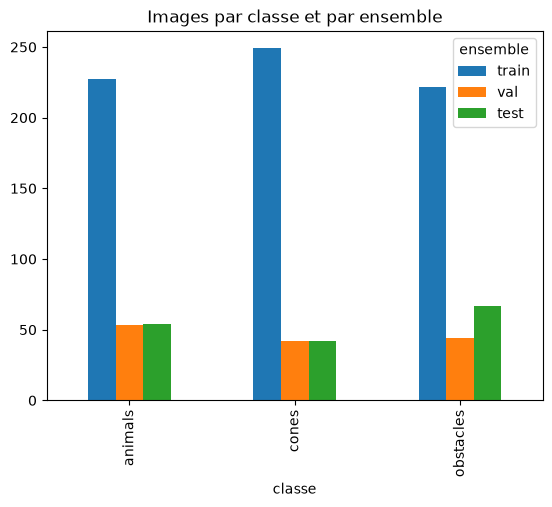

classe,animals,cones,obstacles,All
ensemble,,,,
test,54,42,67,163
train,227,249,222,698
val,53,42,44,139
All,334,333,333,1000


In [2]:
photos = aug.drop_duplicates("source")[["source", "classe"]]
train_p, temp_p = train_test_split(photos, test_size=0.30, stratify=photos["classe"], random_state=42)
val_p, test_p = train_test_split(temp_p, test_size=0.50, stratify=temp_p["classe"], random_state=42)

ensemble = {**dict.fromkeys(train_p.source, "train"), **dict.fromkeys(val_p.source, "val"), **dict.fromkeys(test_p.source, "test")}
aug["ensemble"] = aug["source"].map(ensemble)

pd.crosstab(aug["classe"], aug["ensemble"])[["train", "val", "test"]].plot.bar(title="Images par classe et par ensemble")
plt.show()
pd.crosstab(aug["ensemble"], aug["classe"], margins=True)

**Résultat :** 698 images en train (70 %), 139 en validation (14 %) et 163 en test (16 %). Le découpage est **stratifié** : chaque ensemble contient les 3 classes. Les chiffres ne sont pas parfaitement ronds car on découpe des photos entières avec toutes leurs copies.

### Vérification : aucune photo dans deux ensembles

In [3]:
nb_ensembles = aug.groupby("source")["ensemble"].nunique()
print("Photos présentes dans plusieurs ensembles :", (nb_ensembles > 1).sum())

Photos présentes dans plusieurs ensembles : 0


**Résultat :** 0. Une photo et toutes ses copies sont toujours dans le même ensemble, le test sera donc honnête.

## 2. Redimensionnement 512 × 512 et masque 0 / 1

Image : (512, 512)   Valeurs du masque : [0 1]


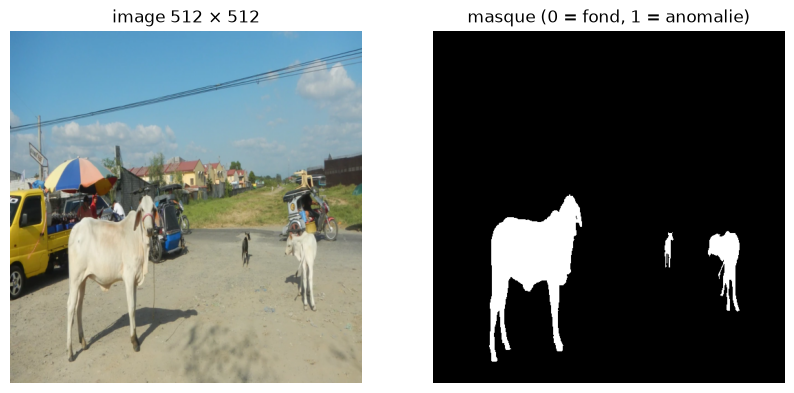

In [4]:
TAILLE = (512, 512)

def preparer(nom):
    img = Image.open(f"{AUG}/{nom}.webp").convert("RGB").resize(TAILLE, Image.BILINEAR)
    masque = Image.open(f"{AUG}/{nom}.labels/labels_semantic.png").resize(TAILLE, Image.NEAREST)
    masque = (np.array(masque) == 2).astype(np.uint8)                 # 2 -> 1 (anomalie), le reste -> 0
    return img, masque

img, masque = preparer(aug.nom.iloc[0])
print("Image :", img.size, "  Valeurs du masque :", np.unique(masque))
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img); ax[0].set_title("image 512 × 512")
ax[1].imshow(masque, cmap="gray"); ax[1].set_title("masque (0 = fond, 1 = anomalie)")
ax[0].axis("off"); ax[1].axis("off")
plt.show()

**Résultat :** l'image passe de 1280 × 720 à 512 × 512 (plus léger pour l'entraînement). Le masque contient seulement 0 et 1, ce que le modèle attend. On utilise `NEAREST` pour ne pas créer de valeurs intermédiaires dans le masque.

## 3. Sauvegarde dans `frames/DataPreparation`

In [5]:
for e in ["train", "val", "test"]:
    os.makedirs(f"{SORTIE}/{e}/images", exist_ok=True)
    os.makedirs(f"{SORTIE}/{e}/masques", exist_ok=True)

for nom, e in zip(aug.nom, aug.ensemble):
    img, masque = preparer(nom)
    img.save(f"{SORTIE}/{e}/images/{nom}.png")
    Image.fromarray(masque).save(f"{SORTIE}/{e}/masques/{nom}.png")

aug.to_csv(f"{SORTIE}/etiquettes.csv", index=False)
for e in ["train", "val", "test"]:
    print(e, ":", len(os.listdir(f"{SORTIE}/{e}/images")), "images")

train : 698 images
val : 139 images
test : 163 images


**Résultat :** chaque ensemble a un dossier `images/` et un dossier `masques/` avec les mêmes noms de fichiers. `etiquettes.csv` donne la classe, la photo d'origine et l'ensemble de chaque image.

## 4. Normalisation
On utilisera un modèle **pré-entraîné sur ImageNet** (transfer learning). Il a appris avec des images normalisées d'une façon précise,
donc on fait pareil : pixels entre 0 et 1, puis on retire la moyenne et on divise par l'écart-type d'ImageNet.

In [6]:
MOYENNE = np.array([0.485, 0.456, 0.406])
ECART = np.array([0.229, 0.224, 0.225])

def normaliser(img):
    x = np.array(img) / 255.0                  # 0..255 -> 0..1
    return (x - MOYENNE) / ECART               # même échelle qu'ImageNet

nom, e = aug.nom.iloc[0], aug.ensemble.iloc[0]
x = normaliser(Image.open(f"{SORTIE}/{e}/images/{nom}.png"))
print(f"Avant : 0 à 255   Après : {x.min():.1f} à {x.max():.1f}, moyenne {x.mean():.2f}")

Avant : 0 à 255   Après : -1.9 à 2.6, moyenne 0.58


**Résultat :** les valeurs sont maintenant centrées autour de 0, comme les images utilisées pour entraîner le modèle pré-entraîné. La normalisation se fait au moment du chargement, on ne la sauvegarde pas sur le disque.

## 5. Vérification finale

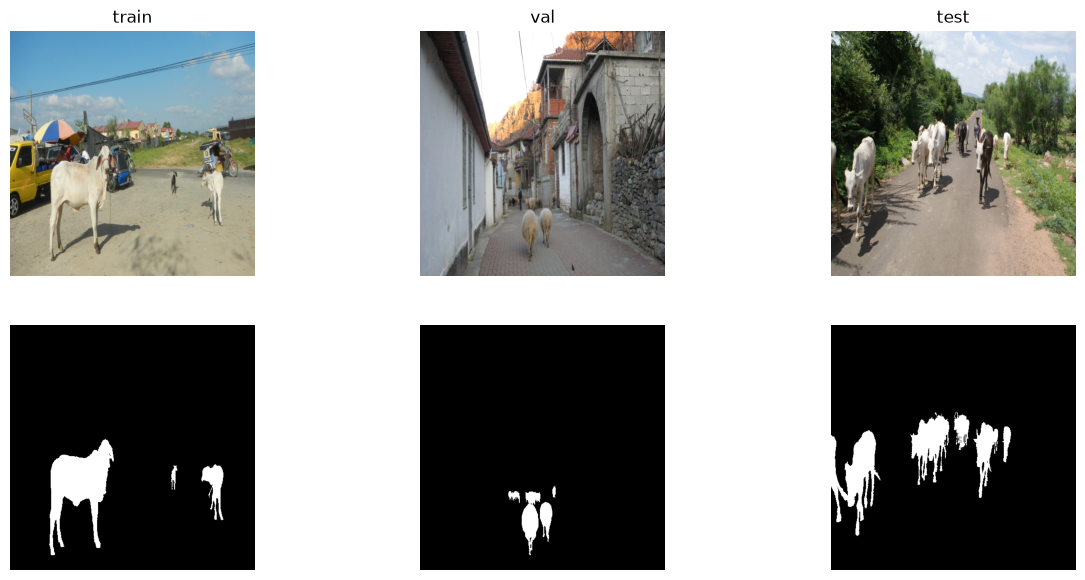

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, e in enumerate(["train", "val", "test"]):
    nom = aug[aug.ensemble == e].nom.iloc[0]
    ax[0, j].imshow(Image.open(f"{SORTIE}/{e}/images/{nom}.png")); ax[0, j].set_title(e)
    ax[1, j].imshow(np.array(Image.open(f"{SORTIE}/{e}/masques/{nom}.png")), cmap="gray")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.show()

**Résultat :** dans chaque ensemble, l'image et son masque se correspondent. Les données sont prêtes pour l'entraînement.

## Conclusion
- Découpage **par photo d'origine** : aucune photo (ni ses copies) dans deux ensembles → test honnête
- Découpage stratifié 70 / 15 / 15 : les 3 classes dans chaque ensemble
- Images en **512 × 512**, masques **0 / 1**
- Normalisation ImageNet au chargement (transfer learning)
- Dataset final dans `frames/DataPreparation/` : `train/`, `val/`, `test/` avec `images/` et `masques/`, plus `etiquettes.csv`
- Étape suivante : entraînement avec la perte **Dice + Focal** et mesure avec **IoU / Dice**